# Лабораторная работа 2

## Полносвязная нейронная сеть

Реализовать нейронную сеть, состоящую из двух полносвязных слоев и решающую задачу классификации на наборе данных из лабораторной работы 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scripts.classifiers.neural_net import TwoLayerNet

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) 
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'


def rel_error(x, y):
    """ returns relative error """
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

1. Добавьте реализации методов класса TwoLayerNet . Проверьте вашу реализацию на модельных данных (Код приведен ниже).  

In [2]:
input_size = 4
hidden_size = 10
num_classes = 3
num_inputs = 5

def init_toy_model():
    np.random.seed(0)
    return TwoLayerNet(input_size, hidden_size, num_classes, std=1e-1)

def init_toy_data():
    np.random.seed(1)
    X = 10 * np.random.randn(num_inputs, input_size)
    y = np.array([0, 1, 2, 2, 1])
    return X, y

net = init_toy_model()
X, y = init_toy_data()

# Прямой проход: вычисление выхода сети

Реализуйте первую часть  метода TwoLayerNet.loss, вычисляющую оценки классов для входных данных. 

Сравните ваш выход сети с эталонными значениями. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-7) .

In [3]:
scores = net.loss(X)
print('Your scores:')
print(scores)
print()
print('correct scores:')
correct_scores = np.asarray([
  [-0.81233741, -1.27654624, -0.70335995],
  [-0.17129677, -1.18803311, -0.47310444],
  [-0.51590475, -1.01354314, -0.8504215 ],
  [-0.15419291, -0.48629638, -0.52901952],
  [-0.00618733, -0.12435261, -0.15226949]])
print(correct_scores)
print()


print('Difference between your scores and correct scores:')
print(np.sum(np.abs(scores - correct_scores)))

Your scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

correct scores:
[[-0.81233741 -1.27654624 -0.70335995]
 [-0.17129677 -1.18803311 -0.47310444]
 [-0.51590475 -1.01354314 -0.8504215 ]
 [-0.15419291 -0.48629638 -0.52901952]
 [-0.00618733 -0.12435261 -0.15226949]]

Difference between your scores and correct scores:
3.6802720745909845e-08



# Прямой проход: вычисление loss

Реализуйте вторую часть метода, вычисляющую значение функции потерь. Сравните с эталоном. Ошибка должна быть очень маленькой (можете ориентироваться на значение < 1e-12) .

In [4]:
loss, _ = net.loss(X, y, reg=0.05)
correct_loss = 1.30378789133

print('Difference between your loss and correct loss:')
print(np.sum(np.abs(loss - correct_loss)))

Difference between your loss and correct loss:
0.01896541960606335


# Обратный проход

Реализуйте третью часть метода loss. Используйте численную реализацию расчета градиента для проверки вашей реализации обратного прохода.  Если прямой и обратный проходы реализованы верно, то ошибка будет < 1e-8 для каждой из переменных W1, W2, b1, и b2. 


In [5]:
from scripts.gradient_check import eval_numerical_gradient

loss, grads = net.loss(X, y, reg=0.05)

for param_name in grads:
    f = lambda W: net.loss(X, y, reg=0.05)[0]
    param_grad_num = eval_numerical_gradient(f, net.params[param_name], verbose=False)
    print('%s max relative error: %e' % (param_name, rel_error(param_grad_num, grads[param_name])))

W2 max relative error: 3.440708e-09
b2 max relative error: 4.447625e-11
W1 max relative error: 3.561318e-09
b1 max relative error: 2.738421e-09


# Обучение нейронной сети на смоделированных данных

Реализуйте методы TwoLayerNet.train и TwoLayerNet.predict. Обучайте сеть до тех пор, пока значение loss не будет < 0.02.


Final training loss:  0.01714364353292376


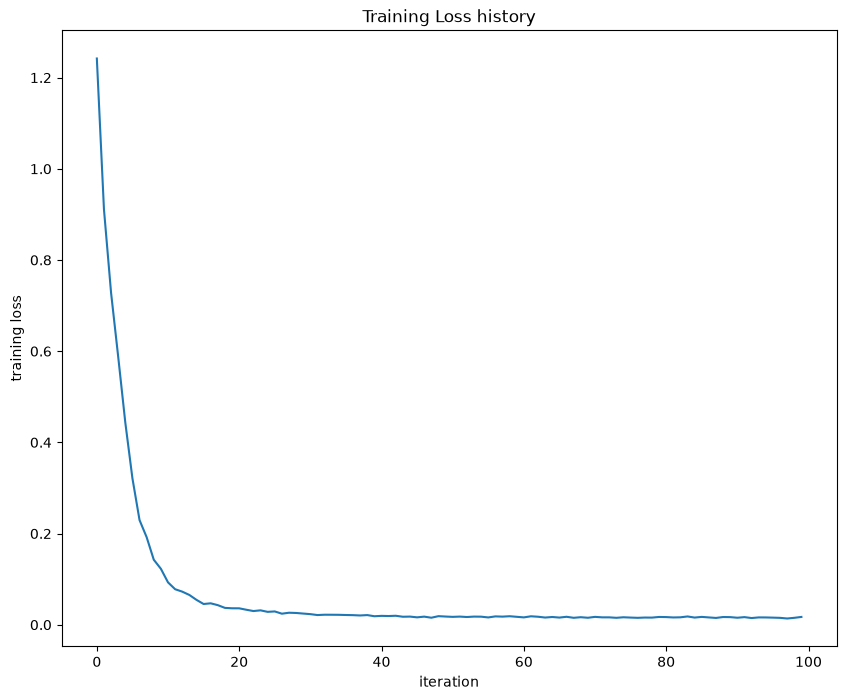

In [6]:
net = init_toy_model()
stats = net.train(X, y, X, y,
            learning_rate=1e-1, reg=5e-6,
            num_iters=100, verbose=False)

print('Final training loss: ', stats['loss_history'][-1])


plt.plot(stats['loss_history'])
plt.xlabel('iteration')
plt.ylabel('training loss')
plt.title('Training Loss history')
plt.show()

# Обучение нейронной сети на реальном наборе данных (CIFAR-10, MNIST)

Загрузите набор данных, соответствующий вашему варианту. 

Разделите данные на обучающую, тестовую и валидационную выборки.

Выполните предобработку данных, как в ЛР 1. 

Обучите нейронную сеть на ваших данных. 

При сдаче лабораторной работы объясните значения всех параметров метода train.

In [7]:
from scripts.data_utils import load_CIFAR10
cifar10_dir = 'scripts/datasets/cifar-10-batches-py'

# Очистка памяти от предыдущих загрузок
try:
    del X_train, y_train, X_test, y_test
    print('Предыдущие данные очищены.')
except:
    pass

# Загрузка данных
X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

print('Размер обучающих данных:  ', X_train.shape)   # (50000, 32, 32, 3)
print('Размер обучающих меток:   ', y_train.shape)   # (50000,)
print('Размер тестовых данных:   ', X_test.shape)    # (10000, 32, 32, 3)
print('Размер тестовых меток:    ', y_test.shape)    # (10000,)

Размер обучающих данных:   (50000, 32, 32, 3)
Размер обучающих меток:    (50000,)
Размер тестовых данных:    (10000, 32, 32, 3)
Размер тестовых меток:     (10000,)


In [8]:
num_training   = 49000
num_validation = 1000

# Валидационная выборка — последние 1000 примеров из train
mask = list(range(num_training, num_training + num_validation))
X_val = X_train[mask]
y_val = y_train[mask]

# Обучающая выборка — первые 49000 примеров
mask = list(range(num_training))
X_train = X_train[mask]
y_train = y_train[mask]

# Тестовая выборка остаётся как есть
# X_test, y_test уже загружены

print('Train data shape: ', X_train.shape)   # (49000, 32, 32, 3)
print('Train labels shape: ', y_train.shape) # (49000,)
print('Val data shape:   ', X_val.shape)     # (1000, 32, 32, 3)
print('Val labels shape: ', y_val.shape)     # (1000,)
print('Test data shape:  ', X_test.shape)    # (10000, 32, 32, 3)
print('Test labels shape: ', y_test.shape)   # (10000,)

Train data shape:  (49000, 32, 32, 3)
Train labels shape:  (49000,)
Val data shape:    (1000, 32, 32, 3)
Val labels shape:  (1000,)
Test data shape:   (10000, 32, 32, 3)
Test labels shape:  (10000,)


In [9]:
X_train = X_train.reshape(X_train.shape[0], -1)
X_val   = X_val.reshape(X_val.shape[0], -1)
X_test  = X_test.reshape(X_test.shape[0], -1)

In [10]:
input_size = 32 * 32 * 3
hidden_size = 50
num_classes = 10
net = TwoLayerNet(input_size, hidden_size, num_classes)

stats = net.train(X_train, y_train, X_val, y_val,
            num_iters=1000, batch_size=200,
            learning_rate=1e-4, learning_rate_decay=0.95,
            reg=0.25, verbose=True)

val_acc = (net.predict(X_val) == y_val).mean()
print('Validation accuracy: ', val_acc)

iteration 0 / 1000: loss 2.302774
iteration 100 / 1000: loss 2.300636
iteration 200 / 1000: loss 2.255748
iteration 300 / 1000: loss 2.120721
iteration 400 / 1000: loss 2.091629
iteration 500 / 1000: loss 2.029904
iteration 600 / 1000: loss 2.033015
iteration 700 / 1000: loss 1.922706
iteration 800 / 1000: loss 1.951045
iteration 900 / 1000: loss 1.895186
Validation accuracy:  0.31


Используя параметры по умолчанию, вы можете получить accuracy, примерно равный 0.29. 

Проведите настройку гиперпараметров для увеличения accuracy. Поэкспериментируйте со значениями гиперпараметров, например, с количеством скрытых слоев, количеством эпох, скорости обучения и др. Ваша цель - максимально увеличить accuracy полносвязной сети на валидационном наборе. Различные эксперименты приветствуются. Например, вы можете использовать методы для сокращения размерности признакового пространства (например, PCA), добавить dropout слои и др. 

Для лучшей модели вычислите acсuracy на тестовом наборе. 

Для отладки процесса обучения часто помогают графики изменения loss и accuracy в процессе обучения. Ниже приведен код построения таких графиков. 

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict

input_size = 32 * 32 * 3
hidden_sizes = [50, 100, 150, 200]
num_classes = 10
num_iters = 5000
batch_size = 200
learning_rates = [5e-4]
regs = [0.2, 0.25, 0.3]
learning_rate_decays = [0.92, 0.95, 0.98]

results = []

for hidden_size in hidden_sizes:
    for learning_rate in learning_rates:
        for reg in regs:
            for learning_rate_decay in learning_rate_decays:

                net = TwoLayerNet(input_size, hidden_size, num_classes)

                stats = net.train(X_train, y_train, X_val, y_val,
                                  num_iters=num_iters,
                                  batch_size=batch_size,
                                  learning_rate=learning_rate,
                                  learning_rate_decay=learning_rate_decay,
                                  reg=reg,
                                  verbose=False)

                val_acc = (net.predict(X_val) == y_val).mean()

                results.append({
                    'hidden_size': hidden_size,
                    'learning_rate': learning_rate,
                    'reg': reg,
                    'learning_rate_decay': learning_rate_decay,
                    'val_acc': val_acc,
                    'stats': stats,      # <-- сохраняем историю обучения
                    'net': net
                })

                print(f'hs={hidden_size}, lr={learning_rate}, '
                      f'reg={reg}, decay={learning_rate_decay} '
                      f'-> val_acc={val_acc:.4f}')

# ---- Сводка по средним (как было) ----
hs_scores = defaultdict(list)
lr_scores = defaultdict(list)
reg_scores = defaultdict(list)
decay_scores = defaultdict(list)

for r in results:
    hs_scores[r['hidden_size']].append(r['val_acc'])
    lr_scores[r['learning_rate']].append(r['val_acc'])
    reg_scores[r['reg']].append(r['val_acc'])
    decay_scores[r['learning_rate_decay']].append(r['val_acc'])

best_hs    = max(hs_scores,    key=lambda k: np.mean(hs_scores[k]))
best_lr    = max(lr_scores,    key=lambda k: np.mean(lr_scores[k]))
best_reg   = max(reg_scores,   key=lambda k: np.mean(reg_scores[k]))
best_decay = max(decay_scores, key=lambda k: np.mean(decay_scores[k]))

print('\nЛучшие параметры по среднему:')
print(f'hidden_size = {best_hs} (mean val_acc = {np.mean(hs_scores[best_hs]):.4f})')
print(f'learning_rate = {best_lr} (mean val_acc = {np.mean(lr_scores[best_lr]):.4f})')
print(f'reg = {best_reg} (mean val_acc = {np.mean(reg_scores[best_reg]):.4f})')
print(f'learning_rate_decay = {best_decay} (mean val_acc = {np.mean(decay_scores[best_decay]):.4f})')

# ---- Выбор ЛУЧШЕЙ модели по val_acc ----
best = max(results, key=lambda r: r['val_acc'])
best_net   = best['net']
best_stats = best['stats']

print('\nЛучшая модель:')
print(f"hidden_size = {best['hidden_size']}")
print(f"learning_rate = {best['learning_rate']}")
print(f"reg = {best['reg']}")
print(f"learning_rate_decay = {best['learning_rate_decay']}")
print(f"val_acc = {best['val_acc']:.4f}")

# ---- Accuracy на тесте ----
test_acc = (best_net.predict(X_test) == y_test).mean()
print(f'test_acc = {test_acc:.4f}')

hs=50, lr=0.0005, reg=0.2, decay=0.92 -> val_acc=0.4840
hs=50, lr=0.0005, reg=0.2, decay=0.95 -> val_acc=0.4690
hs=50, lr=0.0005, reg=0.2, decay=0.98 -> val_acc=0.4550
hs=50, lr=0.0005, reg=0.25, decay=0.92 -> val_acc=0.4770
hs=50, lr=0.0005, reg=0.25, decay=0.95 -> val_acc=0.4800
hs=50, lr=0.0005, reg=0.25, decay=0.98 -> val_acc=0.4590
hs=50, lr=0.0005, reg=0.3, decay=0.92 -> val_acc=0.4550
hs=50, lr=0.0005, reg=0.3, decay=0.95 -> val_acc=0.4290
hs=50, lr=0.0005, reg=0.3, decay=0.98 -> val_acc=0.4610
hs=100, lr=0.0005, reg=0.2, decay=0.92 -> val_acc=0.4940
hs=100, lr=0.0005, reg=0.2, decay=0.95 -> val_acc=0.4890
hs=100, lr=0.0005, reg=0.2, decay=0.98 -> val_acc=0.4890
hs=100, lr=0.0005, reg=0.25, decay=0.92 -> val_acc=0.5030
hs=100, lr=0.0005, reg=0.25, decay=0.95 -> val_acc=0.4970
hs=100, lr=0.0005, reg=0.25, decay=0.98 -> val_acc=0.4700
hs=100, lr=0.0005, reg=0.3, decay=0.92 -> val_acc=0.4930
hs=100, lr=0.0005, reg=0.3, decay=0.95 -> val_acc=0.4700
hs=100, lr=0.0005, reg=0.3, decay=

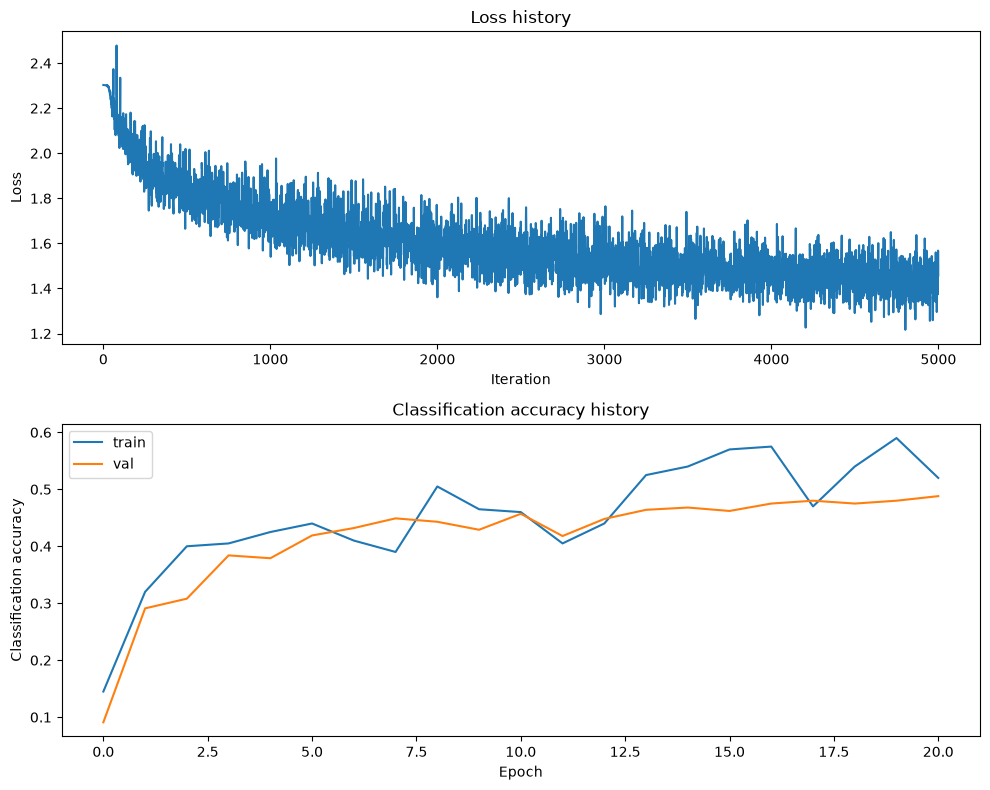

In [25]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 1, 1)
plt.plot(best_stats['loss_history'])
plt.title('Loss history')
plt.xlabel('Iteration')
plt.ylabel('Loss')

plt.subplot(2, 1, 2)
plt.plot(best_stats['train_acc_history'], label='train')
plt.plot(best_stats['val_acc_history'],   label='val')
plt.title('Classification accuracy history')
plt.xlabel('Epoch')
plt.ylabel('Classification accuracy')
plt.legend()

plt.tight_layout()
plt.show()

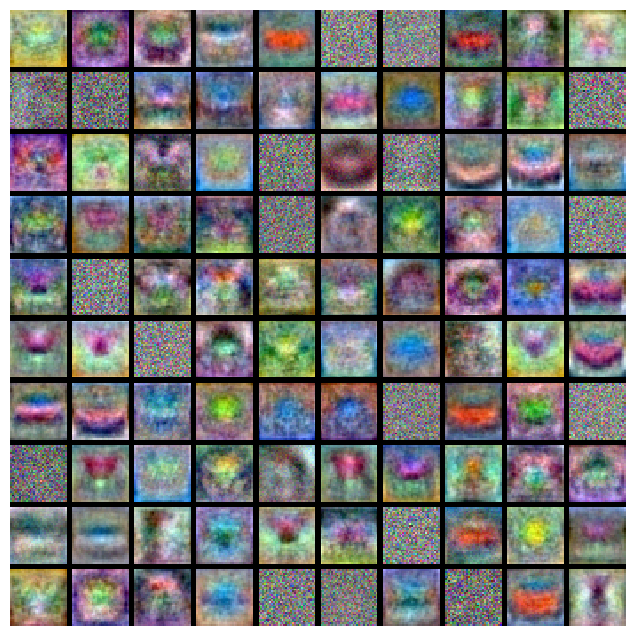

In [26]:
from scripts.vis_utils import visualize_grid

def show_net_weights(net):
    W1 = net.params['W1']
    W1 = W1.reshape(32, 32, 3, -1).transpose(3, 0, 1, 2)
    plt.imshow(visualize_grid(W1, padding=3).astype('uint8'))
    plt.gca().axis('off')
    plt.show()

show_net_weights(best_net)

Сделайте выводы по результатам работы. 

In [ ]:
(лучшая модель: hs=100, lr=5e-4, reg=0.25, decay=0.92), 
Наилучшими по среднему оказались hidden_size=100, reg=0.2, decay=0.92: слишком большая сеть (200) и слишком медленное затухание lr (0.98) стабильно ухудшают результат из-за переобучения и недоиспользования обучения. 
Полносвязная сеть на сырых пикселях CIFAR-10 упирается в потолок ~0.50.

